# Data Preparation for the CNN

Dataset: **Saudi Arabia Public Roads Visual Pollution**

Classes: **barriers**, **sidewalks**, **pothole**

Steps:
1. Load the data
2. Check the labels
3. Remove duplicates and make a train / val / test split
4. Crop the objects
5. Load the crops and add augmentation

In [1]:
%pip install -q kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
import shutil
import hashlib

import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

## 1. Load the data

If the data is already in `data/raw/` we use it, otherwise we download it.

In [3]:
import kagglehub

LOCAL_PATH = "../data/raw/saudi-visual-pollution"

if os.path.isdir(LOCAL_PATH):
    path = LOCAL_PATH
else:
    # Download latest version
    path = kagglehub.dataset_download("fatimsss1111/saudi-arabia-public-roads-visual-pollution-dataset")

print("Path to dataset files:", path)

Path to dataset files: ../data/raw/saudi-visual-pollution


In [4]:
for root, dirs, files in os.walk(path):
    if root.count(os.sep) - path.count(os.sep) < 4:
        print(root, len(files))

../data/raw/saudi-visual-pollution 0
../data/raw/saudi-visual-pollution\Visual Pollution Dataset 1
../data/raw/saudi-visual-pollution\Visual Pollution Dataset\images 0
../data/raw/saudi-visual-pollution\Visual Pollution Dataset\images\train 24553
../data/raw/saudi-visual-pollution\Visual Pollution Dataset\images\val 7242
../data/raw/saudi-visual-pollution\Visual Pollution Dataset\labels 0
../data/raw/saudi-visual-pollution\Visual Pollution Dataset\labels\train 24553


../data/raw/saudi-visual-pollution\Visual Pollution Dataset\labels\val 7242


The labels are in YOLO format. There is a `train` and a `val` folder, but no test folder.

In [5]:
DATA_DIR = os.path.join(path, "Visual Pollution Dataset")
SPLITS = ["train", "val"]

print(open(os.path.join(DATA_DIR, "dataset.yaml")).read())

CLASS_NAMES = ["barriers", "sidewalks", "pothole"]

train: ../datasets/al_round_004/images/train
val: ../datasets/al_round_004/images/val

nc: 3
names: ['barriers', 'sidewalks', 'pothole']


## 2. Check the labels

Each line is one box: `class x_center y_center width height` (between 0 and 1).

In [6]:
label_dir = os.path.join(DATA_DIR, "labels", "train")
label_name = sorted(os.listdir(label_dir))[0]

print(label_name)
print(open(os.path.join(label_dir, label_name)).read())

DATA-WORKATTACH-FILE MOMRA-OPS-CS-WORK INC-21-06-038549!20210610T165255.438 GMT.txt
1 0.550482 0.374290 0.503576 0.726397


In [7]:
missing = 0
empty = 0
invalid = 0

for split in SPLITS:
    counts = {name: 0 for name in CLASS_NAMES}
    image_names = os.listdir(os.path.join(DATA_DIR, "images", split))

    for image_name in image_names:
        label_path = os.path.join(DATA_DIR, "labels", split, image_name[:-4] + ".txt")
        if not os.path.exists(label_path):
            missing += 1
            continue

        lines = [line.split() for line in open(label_path) if line.strip()]
        if len(lines) == 0:
            empty += 1

        for parts in lines:
            values = [float(v) for v in parts[1:]]
            if len(parts) != 5 or int(parts[0]) not in [0, 1, 2] or min(values) < 0 or max(values) > 1:
                invalid += 1
            else:
                counts[CLASS_NAMES[int(parts[0])]] += 1

    print(split, len(image_names), "images", counts)

print("Missing label files:", missing)
print("Empty label files:", empty)
print("Invalid lines:", invalid)

train 24553 images {'barriers': 6579, 'sidewalks': 5663, 'pothole': 19960}


val 7242 images {'barriers': 1838, 'sidewalks': 1749, 'pothole': 6015}
Missing label files: 0
Empty label files: 0
Invalid lines: 0


Some boxes from each class:

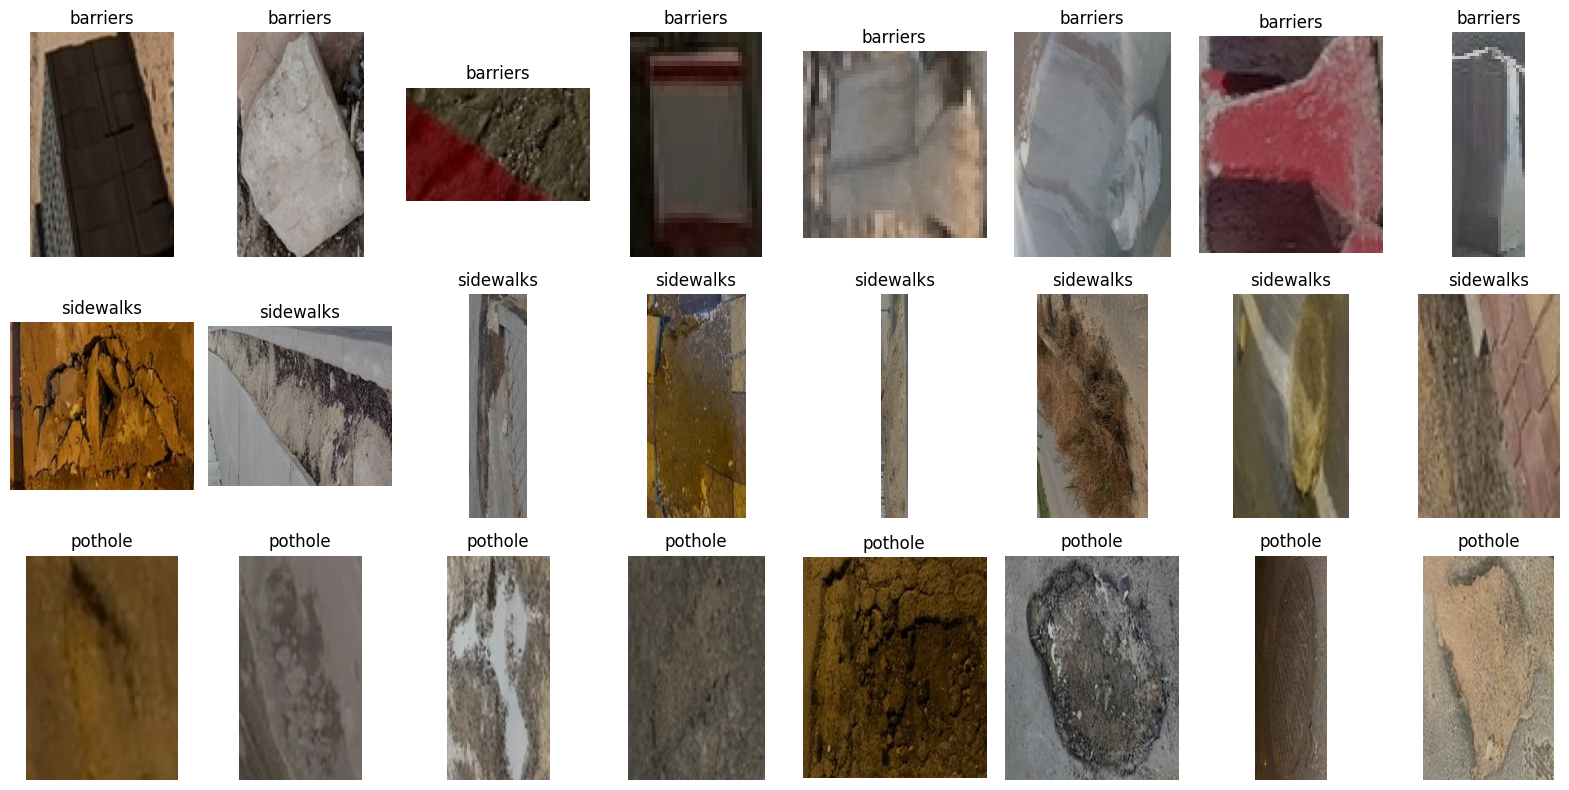

In [8]:
random.seed(0)
label_dir = os.path.join(DATA_DIR, "labels", "train")
image_dir = os.path.join(DATA_DIR, "images", "train")

boxes = {0: [], 1: [], 2: []}
for label_name in os.listdir(label_dir):
    for line in open(os.path.join(label_dir, label_name)):
        parts = line.split()
        if len(parts) == 5:
            boxes[int(parts[0])].append((label_name[:-4] + ".jpg", *map(float, parts[1:])))

plt.figure(figsize=(16, 8))
for class_id in range(3):
    for col, (image_name, x, y, w, h) in enumerate(random.sample(boxes[class_id], 8)):
        img = cv2.imread(os.path.join(image_dir, image_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        x1, y1 = max(int((x - w / 2) * W), 0), max(int((y - h / 2) * H), 0)
        x2, y2 = int((x + w / 2) * W), int((y + h / 2) * H)

        plt.subplot(3, 8, class_id * 8 + col + 1)
        plt.imshow(img[y1:y2, x1:x2])
        plt.title(CLASS_NAMES[class_id])
        plt.axis("off")
plt.tight_layout()
plt.show()

The classes look right: concrete barriers, broken sidewalks and holes in the road.

## 3. Remove duplicates and make a new split

**Duplicates.** Some photos are saved twice, sometimes once in train and once in val.
Then the model is tested on photos it has already seen. We find them by comparing the file content (MD5 hash).

In [9]:
hashes = {}

for split in SPLITS:
    image_dir = os.path.join(DATA_DIR, "images", split)
    for image_name in os.listdir(image_dir):
        with open(os.path.join(image_dir, image_name), "rb") as f:
            md5 = hashlib.md5(f.read()).hexdigest()
        if md5 not in hashes:
            hashes[md5] = []
        hashes[md5].append((split, image_name))

duplicates = [group for group in hashes.values() if len(group) > 1]
in_both = [group for group in duplicates if len(set(s for s, n in group)) > 1]

print("Unique photos:", len(hashes))
print("Photos saved more than once:", len(duplicates))
print("...in both train and val:", len(in_both))

Unique photos: 30524
Photos saved more than once: 1250
...in both train and val: 1153


**Reports.** The part of the file name before `!` is the report (e.g. `... INC-21-06-038549`).
One report can have several photos of the same place, so all photos of a report must be in the same split.

In [10]:
train_reports = set(n.split("!")[0] for n in os.listdir(os.path.join(DATA_DIR, "images", "train")))
val_reports = set(n.split("!")[0] for n in os.listdir(os.path.join(DATA_DIR, "images", "val")))

print("Reports in both train and val:", len(train_reports & val_reports))

Reports in both train and val: 1648


**New split.** We keep one copy of each photo and split the **reports** into 70% train, 15% val and 15% test.

In [11]:
images = sorted(group[0] for group in hashes.values())   # one copy of each photo

reports = sorted(set(name.split("!")[0] for split, name in images))
random.seed(42)
random.shuffle(reports)

n_train = int(0.70 * len(reports))
n_val = int(0.15 * len(reports))

new_split = {}
for i, report in enumerate(reports):
    if i < n_train:
        new_split[report] = "train"
    elif i < n_train + n_val:
        new_split[report] = "val"
    else:
        new_split[report] = "test"

NEW_SPLITS = ["train", "val", "test"]
for s in NEW_SPLITS:
    print(s, sum(1 for split, name in images if new_split[name.split("!")[0]] == s), "images")

train 21395 images
val 4562 images
test 4567 images


**Boxes with two labels.** A few objects have two almost identical boxes with **different** classes.
We don't know which label is right, so we skip them.
We compare boxes with IoU (how much two boxes overlap, from 0 to 1).

In [12]:
def iou(a, b):
    ax1, ay1, ax2, ay2 = a[0] - a[2] / 2, a[1] - a[3] / 2, a[0] + a[2] / 2, a[1] + a[3] / 2
    bx1, by1, bx2, by2 = b[0] - b[2] / 2, b[1] - b[3] / 2, b[0] + b[2] / 2, b[1] + b[3] / 2
    inter = max(0, min(ax2, bx2) - max(ax1, bx1)) * max(0, min(ay2, by2) - max(ay1, by1))
    union = a[2] * a[3] + b[2] * b[3] - inter
    return inter / union


image_boxes = {}   # (split, image_name) -> boxes we keep
skipped_boxes = 0

for split, image_name in images:
    label_path = os.path.join(DATA_DIR, "labels", split, image_name[:-4] + ".txt")
    boxes = []
    for line in open(label_path):
        parts = line.split()
        if len(parts) == 5:
            boxes.append((int(parts[0]), *map(float, parts[1:])))

    keep = []
    for b in boxes:
        two_labels = False
        for other in boxes:
            if other[0] != b[0] and iou(b[1:], other[1:]) > 0.7:
                two_labels = True
        if two_labels:
            skipped_boxes += 1
        else:
            keep.append(b)
    image_boxes[(split, image_name)] = keep

print("Boxes skipped:", skipped_boxes)

Boxes skipped: 260


## 4. Crop the objects

For each box: cut it out, add gray borders to make it square (so it is not stretched), and resize to 224 x 224.
Boxes smaller than 16 pixels are skipped.

In [13]:
IMG_SIZE = 224
MIN_BOX = 16

OUTPUT_DIR = "../data/processed" if os.path.isdir("../data") else "."
CROP_DIR = os.path.join(OUTPUT_DIR, "crops")

# remove old crops from an earlier run
if os.path.exists(CROP_DIR):
    shutil.rmtree(CROP_DIR)

for s in NEW_SPLITS:
    for name in CLASS_NAMES:
        os.makedirs(os.path.join(CROP_DIR, s, name))

saved = {s: 0 for s in NEW_SPLITS}
too_small = 0

for split, image_name in images:
    s = new_split[image_name.split("!")[0]]
    img = cv2.imread(os.path.join(DATA_DIR, "images", split, image_name))
    H, W = img.shape[:2]

    for k, (class_id, x, y, w, h) in enumerate(image_boxes[(split, image_name)]):
        x, y, w, h = x * W, y * H, w * W, h * H
        x1, y1 = max(int(x - w / 2), 0), max(int(y - h / 2), 0)
        x2, y2 = min(int(x + w / 2), W), min(int(y + h / 2), H)
        if max(x2 - x1, y2 - y1) < MIN_BOX or x2 <= x1 or y2 <= y1:
            too_small += 1
            continue

        crop = img[y1:y2, x1:x2]

        # gray borders to make it square
        ch, cw = crop.shape[:2]
        side = max(ch, cw)
        top = (side - ch) // 2
        left = (side - cw) // 2
        crop = cv2.copyMakeBorder(crop, top, side - ch - top, left, side - cw - left,
                                  cv2.BORDER_CONSTANT, value=(114, 114, 114))
        crop = cv2.resize(crop, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

        out_name = image_name[:-4] + "_" + str(k) + ".jpg"
        cv2.imwrite(os.path.join(CROP_DIR, s, CLASS_NAMES[class_id], out_name), crop)
        saved[s] += 1

print("Crops saved:", saved)
print("Too small:", too_small)

Crops saved: {'train': 27883, 'val': 5793, 'test': 5871}
Too small: 124


In [14]:
for s in NEW_SPLITS:
    counts = {name: len(os.listdir(os.path.join(CROP_DIR, s, name))) for name in CLASS_NAMES}
    print(s, counts)

train {'barriers': 5549, 'sidewalks': 4961, 'pothole': 17373}
val {'barriers': 1151, 'sidewalks': 944, 'pothole': 3698}
test {'barriers': 1204, 'sidewalks': 974, 'pothole': 3693}


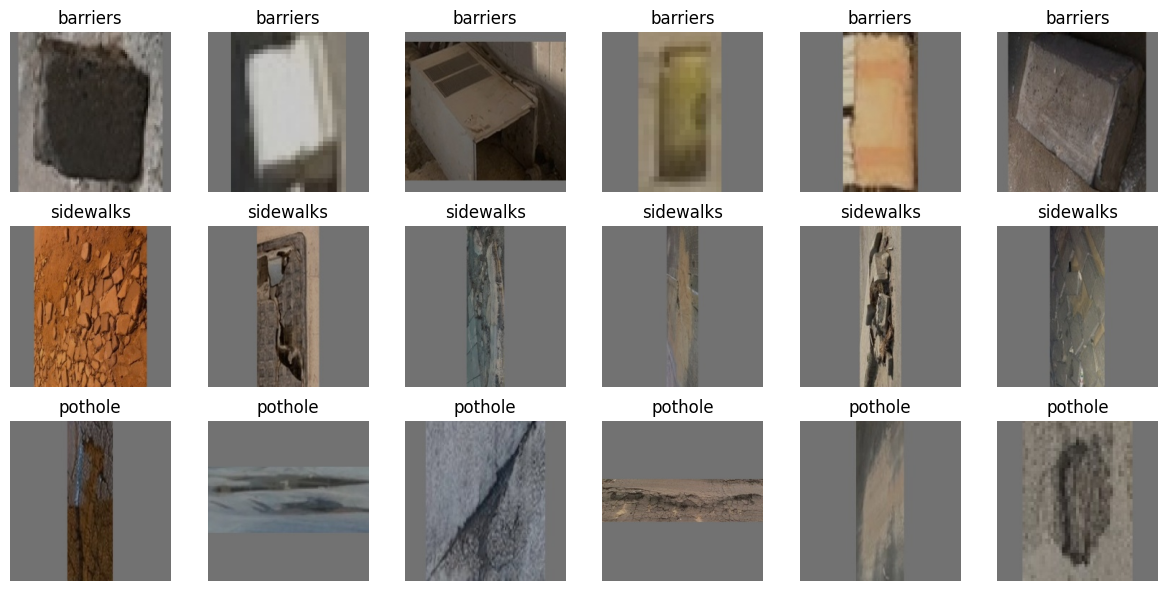

In [15]:
random.seed(1)
plt.figure(figsize=(12, 6))
for row, name in enumerate(CLASS_NAMES):
    folder = os.path.join(CROP_DIR, "train", name)
    for col, crop_name in enumerate(random.sample(os.listdir(folder), 6)):
        crop = cv2.imread(os.path.join(folder, crop_name))
        plt.subplot(3, 6, row * 6 + col + 1)
        plt.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        plt.title(name)
        plt.axis("off")
plt.tight_layout()
plt.show()

Check that no photo is in two splits:

In [16]:
photos = {}
for s in NEW_SPLITS:
    photos[s] = set()
    for name in CLASS_NAMES:
        for crop_name in os.listdir(os.path.join(CROP_DIR, s, name)):
            photos[s].add(crop_name.rsplit("_", 1)[0])

print("train & val :", len(photos["train"] & photos["val"]))
print("train & test:", len(photos["train"] & photos["test"]))
print("val & test  :", len(photos["val"] & photos["test"]))

train & val : 0
train & test: 0
val & test  : 0


## 5. Load the crops

In [17]:
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CROP_DIR, "train"), class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=True, seed=42)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CROP_DIR, "val"), class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(CROP_DIR, "test"), class_names=CLASS_NAMES,
    image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE, shuffle=False)

Found 27883 files belonging to 3 classes.


Found 5793 files belonging to 3 classes.


Found 5871 files belonging to 3 classes.


There are many more potholes than barriers or sidewalks, so we use class weights in training.

In [18]:
train_counts = np.array([len(os.listdir(os.path.join(CROP_DIR, "train", name))) for name in CLASS_NAMES])
class_weight = {i: train_counts.sum() / (len(CLASS_NAMES) * c) for i, c in enumerate(train_counts)}

for i, name in enumerate(CLASS_NAMES):
    print(name, train_counts[i], "crops, weight", round(class_weight[i], 2))

barriers

 5549 crops, weight 1.67
sidewalks 4961 crops, weight 1.87
pothole 17373 crops, weight 0.53


## 6. Data augmentation

Small random changes to the training images during training (only for train):

- horizontal flip
- small rotation (about 10 degrees), because phone photos are often a bit tilted
- brightness and contrast, for different light and cameras

In [19]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.03, fill_mode="constant", fill_value=114.0),
    tf.keras.layers.RandomBrightness(0.2),
    tf.keras.layers.RandomContrast(0.2),
])

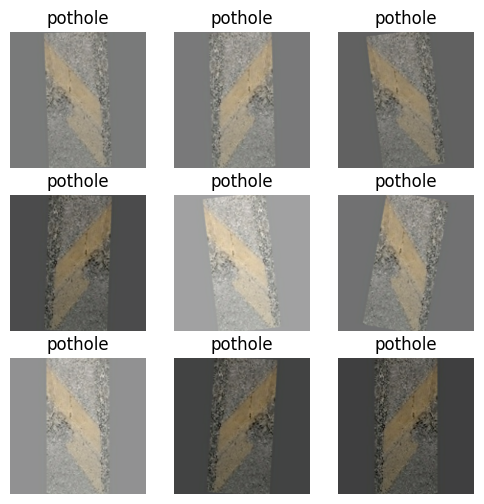

In [20]:
images_batch, labels_batch = next(iter(train_ds))

plt.figure(figsize=(6, 6))
for i in range(9):
    augmented = data_augmentation(images_batch[:1], training=True)
    plt.subplot(3, 3, i + 1)
    plt.imshow(augmented[0].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(labels_batch[0])])
    plt.axis("off")
plt.show()

## Summary

- Crops are saved in `crops/train`, `crops/val` and `crops/test`, one folder per class, 224 x 224.
- Duplicates are removed and the split is made by report, so there is no leakage.
- In training: use `data_augmentation` on train only, the model's `preprocess_input`, and `class_weight`.